# Part A – Optical Sensor Heart Rate

## A.1 Load the data
The CSV has no header and two columns: time (s) and reflected light intensity.
The sampling rate is computed from the mean time step between samples.

In [9]:
import numpy as np                      # numerical arrays and maths
import pandas as pd                     # reading the CSV file
import matplotlib.pyplot as plt         # plotting
from scipy.signal import butter, filtfilt, detrend, find_peaks  # signal processing tools
HR_BAND = (0.7, 3.0)                    # physiological heart-rate band in Hz (42–180 bpm)

def load_signal(path):
    """Load the optical sensor CSV and return time, signal and sampling rate."""
    df = pd.read_csv(path, header=None, names=["time", "amplitude"])  # file has no header row
    t = df["time"].to_numpy()           # time stamps in seconds
    x = df["amplitude"].to_numpy()      # reflected light intensity
    fs = 1 / np.mean(np.diff(t))        # sampling rate = 1 / mean time step
    return t, x, fs


t, x, fs = load_signal("data/heart_beat_signal.csv")                  # load the data
print(f"{len(t)} samples, fs = {fs:.2f} Hz, duration = {t[-1]:.1f} s")  # quick sanity check

913 samples, fs = 29.97 Hz, duration = 30.5 s


## A.2 Plot the raw signal (Task 1.1)
The raw reflected-light intensity is plotted against time to inspect the signal quality before processing.

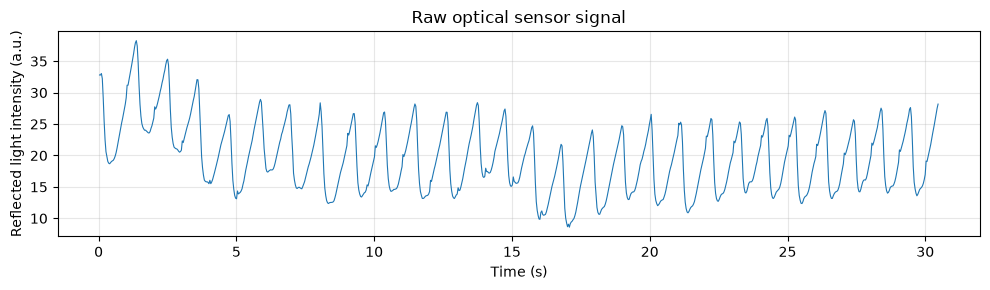

In [10]:
fig, ax = plt.subplots(figsize=(10, 3))                  # wide figure suits a time series
ax.plot(t, x, linewidth=0.8)                             # raw signal against time
ax.set_xlabel("Time (s)")                                # x-axis label with units
ax.set_ylabel("Reflected light intensity (a.u.)")        # a.u. = arbitrary units
ax.set_title("Raw optical sensor signal")                # figure title
ax.grid(alpha=0.3)                                       # light grid makes values easier to read
fig.tight_layout()                                       # stop labels being cut off
fig.savefig("figures/A1_raw_signal.png", dpi=200)        # save a high-resolution copy for the report
plt.show()                                               # display the figure in the notebook

## A.3 Pre-processing: detrending and band-pass filtering
A linear trend is removed to correct baseline drift. A zero-phase Butterworth band-pass filter (0.7–3 Hz, i.e. 42–180 bpm) then keeps only frequencies in the physiological heart-rate range, removing respiration and high-frequency noise.

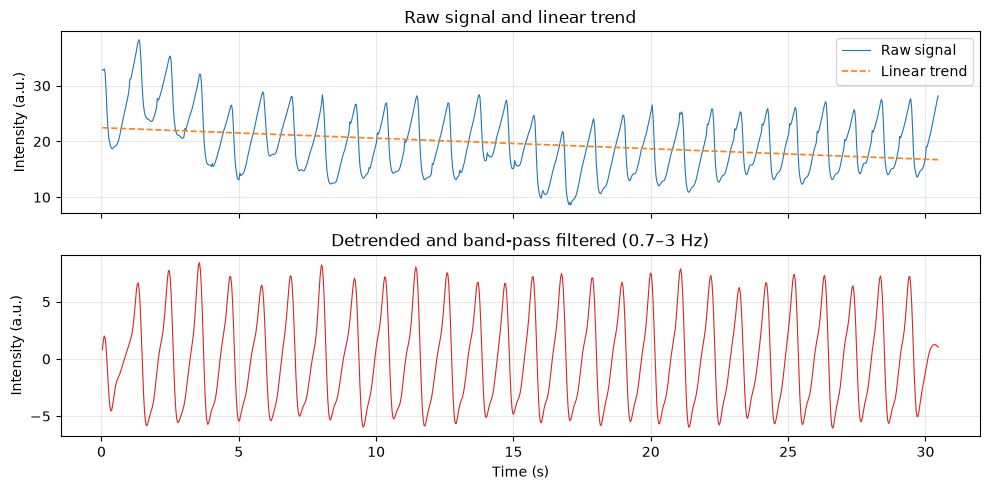

In [11]:
def bandpass(signal, fs, band=HR_BAND, order=3):
    """Zero-phase Butterworth band-pass filter keeping the heart-rate band."""
    b, a = butter(order, band, btype="band", fs=fs)  # design the filter coefficients
    return filtfilt(b, a, signal)                    # filter forwards and backwards: no time delay                             


x_detrended = detrend(x)                     # remove the linear baseline drift
trend = x - x_detrended                      # the straight line that was removed (for plotting)
x_filtered = bandpass(x_detrended, fs)       # keep only 0.7–3 Hz (42–180 bpm)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)        # two panels sharing the time axis

axes[0].plot(t, x, linewidth=0.8, label="Raw signal")                # top: raw data
axes[0].plot(t, trend, "--", linewidth=1.2, label="Linear trend")    # top: the drift being removed
axes[0].set_ylabel("Intensity (a.u.)")
axes[0].set_title("Raw signal and linear trend")
axes[0].legend(loc="upper right")
axes[0].grid(alpha=0.3)

axes[1].plot(t, x_filtered, color="tab:red", linewidth=0.8)          # bottom: cleaned signal
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Intensity (a.u.)")
axes[1].set_title("Detrended and band-pass filtered (0.7–3 Hz)")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("figures/A2_filtered_signal.png", dpi=200)               # save for the report
plt.show()

## A.4 Heart rate from the frequency spectrum (Task 1.2)
The filtered signal is transformed with the Fast Fourier Transform (FFT). A periodic heartbeat appears as a peak in the amplitude spectrum; the frequency of the largest peak inside the 0.7–3 Hz band is the dominant cardiac frequency $f_{HR}$, and the heart rate is $HR = 60 \times f_{HR}$ bpm.
The frequency resolution is $\Delta f = f_s / N$, so the bpm estimate is only precise to about $\pm 60\,\Delta f / 2$.


FFT heart rate = 55.1 bpm
Frequency resolution = 0.033 Hz (±1.0 bpm)


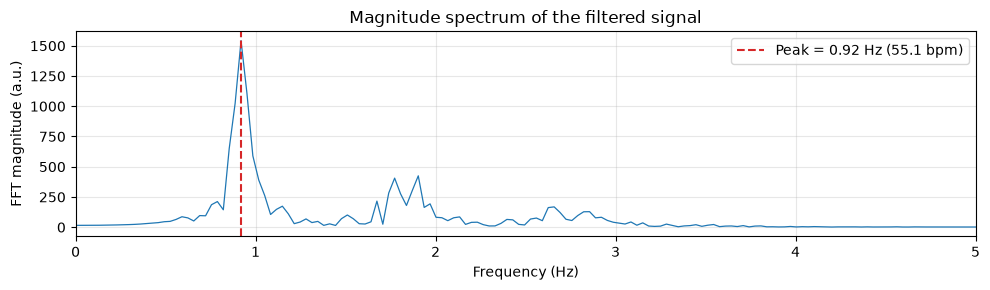

In [12]:
def estimate_hr_fft(signal, fs, band=HR_BAND):
    """Estimate heart rate (bpm) from the largest spectral peak inside the heart-rate band."""
    magnitude = np.abs(np.fft.rfft(signal))                    # magnitude spectrum (positive frequencies only)
    freqs = np.fft.rfftfreq(len(signal), d=1 / fs)             # frequency of each FFT bin (Hz)
    in_band = (freqs >= band[0]) & (freqs <= band[1])          # mask for the heart-rate band
    f_peak = freqs[in_band][np.argmax(magnitude[in_band])]     # dominant cardiac frequency
    return f_peak * 60, f_peak, freqs, magnitude               # bpm, Hz, and spectrum for plotting


hr_fft, f_peak, freqs, magnitude = estimate_hr_fft(x_filtered, fs)               # run on the optical signal
print(f"FFT heart rate = {hr_fft:.1f} bpm")
print(f"Frequency resolution = {fs / len(x_filtered):.3f} Hz "
      f"(±{30 * fs / len(x_filtered):.1f} bpm)")                                 # half a bin, in bpm

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(freqs, magnitude, linewidth=0.9)             # rfft already returns only non-negative frequencies
ax.axvline(f_peak, color="tab:red", linestyle="--",
           label=f"Peak = {f_peak:.2f} Hz ({hr_fft:.1f} bpm)")
ax.set_xlim(0, 5)                                    # the heart-rate peak is well below 5 Hz
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (a.u.)")
ax.set_title("Magnitude spectrum of the filtered signal")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/A3_fft_spectrum.png", dpi=200)
plt.show()


Observation from Xiaoan Shi: Calculating approximately 27 cycles within 30s yields a rate of around 54 bpm, which is close to the value estimated from FFT. A peak of approximately 1.8 Hz corresponds to a rate of around 108 bpm, which is roughly double the visible rate in the original tracking.

## A.5 Validation with peak detection
As an independent check, individual heartbeats are found in the time domain with `find_peaks`. Peaks must be at least int(fs × 60 / 180) = 9 samples (0.30 s) apart, so no faster than about 180 bpm and higher than one standard deviation of the signal, so small bumps at the start and end are ignored. The mean time between beats gives a second heart-rate estimate, which should agree with the FFT result.


27 beats detected, heart rate = 55.5 bpm
Difference from FFT = 0.4 bpm


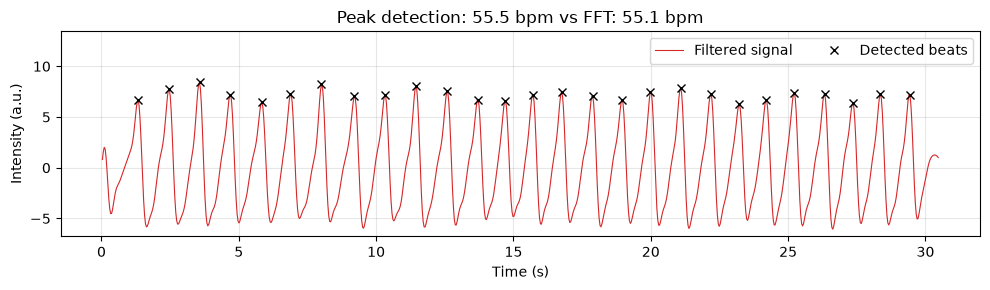

In [13]:
def estimate_hr_peaks(signal, t, fs, max_bpm=180):
    """Estimate heart rate (bpm) from the mean interval between detected beats."""
    min_gap = int(fs * 60 / max_bpm)                            # minimum samples between beats
    peaks, _ = find_peaks(signal, distance=min_gap,
                          height=np.std(signal))                # ignore small bumps at the edges
    ibi = np.diff(t[peaks])                                     # inter-beat intervals (s)
    return 60 / np.mean(ibi), peaks, ibi                        # bpm, beat indices, intervals


hr_peaks, peaks, ibi = estimate_hr_peaks(x_filtered, t, fs)                      # run on the optical signal
print(f"{len(peaks)} beats detected, heart rate = {hr_peaks:.1f} bpm")
print(f"Difference from FFT = {abs(hr_peaks - hr_fft):.1f} bpm")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, x_filtered, color="tab:red", linewidth=0.8, label="Filtered signal")
ax.plot(t[peaks], x_filtered[peaks], "kx", markersize=6, label="Detected beats")
ax.set_ylim(top=1.6 * x_filtered.max())  # leave room so the legend does not cover any beats
ax.set_xlabel("Time (s)")
ax.set_ylabel("Intensity (a.u.)")
ax.set_title(f"Peak detection: {hr_peaks:.1f} bpm vs FFT: {hr_fft:.1f} bpm")
ax.legend(loc="upper right", ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/A4_peak_detection.png", dpi=200)
plt.show()


## A.6 Summary of Part A
Both methods give consistent heart-rate estimates. The results and the filtered signal are saved to `data/` so they can be reused and submitted.

In [14]:
results_A = pd.DataFrame({
    "method": ["FFT", "Peak detection"],
    "heart_rate_bpm": [round(hr_fft, 1), round(hr_peaks, 1)],
})                                                                     # one row per method
print(results_A.to_string(index=False))                               # show the table without row numbers

beat_hr = 60 / ibi                                                     # heart rate of each individual beat
print(f"Beat-to-beat heart rate: {beat_hr.mean():.1f} ± {beat_hr.std():.1f} bpm (mean ± SD)")

results_A.to_csv("data/partA_results.csv", index=False)                # save the results table
pd.DataFrame({"time_s": t, "filtered_signal": x_filtered}).to_csv(
    "data/partA_filtered_signal.csv", index=False)                    # save the processed signal

        method  heart_rate_bpm
           FFT            55.1
Peak detection            55.5
Beat-to-beat heart rate: 55.7 ± 3.1 bpm (mean ± SD)


Explaination by Xiaoan Shi: The difference between these two estimates is 0.4 bpm, which is less than the interval of approximately 2 bpm between adjacent FFT bins. Their agreement supports a recorded estimate of approxiemately 55 bpm. An independent reference measurement is required to determine the actual error.

# Part B – Video Heart Rate

## B.1 Load the video and extract the mean grayscale per frame
A fingertip pressed on the phone camera (with the flash on) is lit from behind. Each heartbeat changes how much blood is in the fingertip, which slightly changes how much light reaches the sensor. Averaging every pixel of a frame to a single number turns the video into a 1-D time series, just like the optical sensor signal in Part A.

The sampling rate is the video frame rate, and the time of frame *i* is *i / fps*.

Part B reuses the imports, `HR_BAND` and the `bandpass` function defined in Part A, so the notebook should be run from the top (Restart & Run All).
Videos must provide at least 10 seconds of decodable frames and a finite frame rate above 6 Hz. Empty, short or flat recordings raise a clear error.


In [15]:
import cv2                              # OpenCV: reads the video frame by frame

VIDEO_PATH = "data/video_of_finger.MOV" # video is not in git (118 MB); download it from Moodle


def load_video_signal(path):
    """Return time (s), mean grayscale value per frame, and frame rate (fps)."""
    cap = cv2.VideoCapture(path)                              # open the video file
    try:
        if not cap.isOpened():
            raise FileNotFoundError(f"Cannot open {path}")        # clear error if the file is missing
        fps = cap.get(cv2.CAP_PROP_FPS)                           # frames per second = sampling rate
        if not np.isfinite(fps) or fps <= 2 * HR_BAND[1]:         # Nyquist: must sample above 6 Hz
            raise ValueError("Video frame rate must be finite and above 6 Hz.")
        means = []
        while True:
            ok, frame = cap.read()                                # read the next frame (BGR image)
            if not ok:                                            # no more frames
                break
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)        # colour -> grayscale
            means.append(gray.mean())                             # average over all pixels in the frame
    finally:
        cap.release()                                             # release even if decoding or validation fails

    # Ten seconds gives at least seven cycles at the lower band edge (0.7 Hz).
    if len(means) < int(np.ceil(10 * fps)):
        raise ValueError("Video must contain at least 10 seconds of decodable frames.")
    v = np.array(means)
    if np.std(v) < 1e-8:                                          # numerical tolerance, not a physiological threshold
        raise ValueError("Cannot estimate heart rate: video signal has no usable variation.")
    t = np.arange(len(v)) / fps                                   # time of each frame in seconds
    return t, v, fps


t_v, v, fs_v = load_video_signal(VIDEO_PATH)
print(f"{len(t_v)} frames, fps = {fs_v:.2f} Hz, duration = {t_v[-1]:.1f} s")  # quick sanity check

1852 frames, fps = 29.98 Hz, duration = 61.7 s


## B.2 Plot the mean grayscale signal (Task 1)
The mean grayscale value of each frame is plotted against time in seconds.

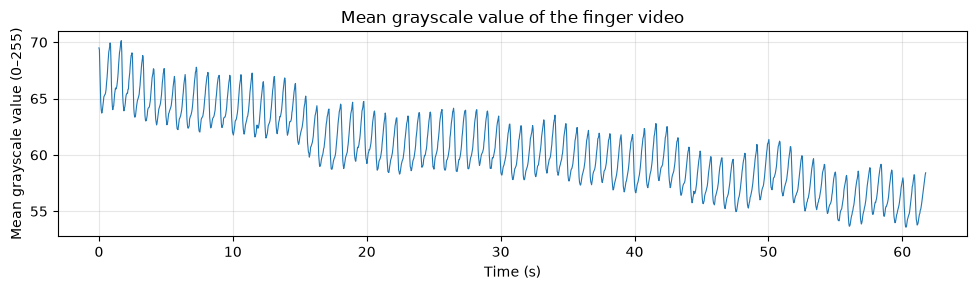

In [16]:
fig, ax = plt.subplots(figsize=(10, 3))                  # wide figure suits a time series
ax.plot(t_v, v, linewidth=0.8)                           # mean grayscale per frame
ax.set_xlabel("Time (s)")                                # x-axis label with units
ax.set_ylabel("Mean grayscale value (0–255)")            # 8-bit grayscale range
ax.set_title("Mean grayscale value of the finger video")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/B1_raw_video_signal.png", dpi=200)  # high-resolution copy for the report
plt.show()

pd.DataFrame({"time_s": t_v, "mean_gray": v}).to_csv(
    "data/partB_mean_gray.csv", index=False)             # save so filtering/FFT can reuse it without re-reading the video

## B.3 Pre-processing: detrending and band-pass filtering
The raw video signal drifts downwards over the minute (e.g. the finger pressure or the camera's auto-exposure changes). This slow drift is far larger than the pulse and would dominate the low-frequency end of the spectrum, so it is removed first. The same `bandpass` function and 0.7–3 Hz heart-rate band as in Part A are then applied. The video frame rate (about 30 Hz) is well above the 6 Hz needed to sample frequencies up to 3 Hz (Nyquist).

An error is raised if no variation is left after detrending (e.g. a recording that is only a brightness drift) or after filtering. This tolerance only rules out numerical residue; it does not prove that the remaining signal is a pulse.

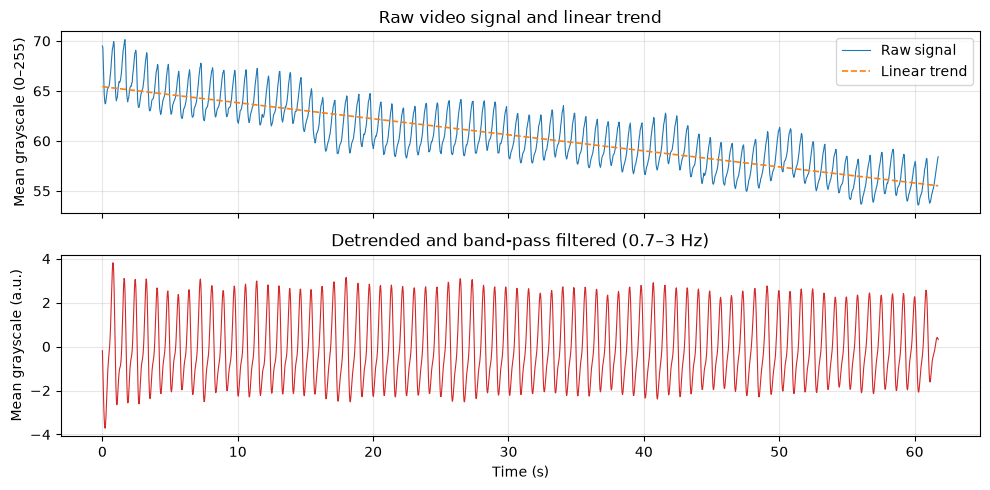

In [17]:
v_detrended = detrend(v)                     # remove the linear baseline drift
if np.std(v_detrended) < 1e-8:               # numerical tolerance only: a pure drift leaves nothing
    raise ValueError("No usable pulse variation after detrending.")

trend_v = v - v_detrended                    # the straight line that was removed (for plotting)
v_filtered = bandpass(v_detrended, fs_v)     # keep only 0.7–3 Hz (42–180 bpm)
if np.std(v_filtered) < 1e-8:                # does not prove the remaining signal is a pulse
    raise ValueError("No usable signal after filtering.")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)        # two panels sharing the time axis

axes[0].plot(t_v, v, linewidth=0.8, label="Raw signal")              # top: raw data
axes[0].plot(t_v, trend_v, "--", linewidth=1.2, label="Linear trend")  # top: the drift being removed
axes[0].set_ylabel("Mean grayscale (0–255)")
axes[0].set_title("Raw video signal and linear trend")
axes[0].legend(loc="upper right")
axes[0].grid(alpha=0.3)

axes[1].plot(t_v, v_filtered, color="tab:red", linewidth=0.8)        # bottom: cleaned signal
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Mean grayscale (a.u.)")
axes[1].set_title("Detrended and band-pass filtered (0.7–3 Hz)")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("figures/B2_filtered_video_signal.png", dpi=200)         # save for the report
plt.show()

Observation and explanation: At around 15-16s, the average brightness decreases while the pulsating oscillation continues. When the overall downward trend os factored out, only a small part of this local variation remains. As each frame is represented by an average value, we need to examine the raw frame at that point to determine whether the brightness has changed across the entire image or only in a specific region.

## B.4 Check the inputs for the remaining tasks

Run the notebook from the top. B.1 supplies `t_v`, `v`, and `fs_v`; B.3 already supplies `v_filtered`. The existing detrending and filtering code is retained. The inherited 0.7–3Hz band is a working search range (42–180bpm), not a universal physiological limit. Constant frame spacing is assumed; variable-frame-rate video would require timestamp checks/resampling.

In [ ]:
t_v = np.asarray(t_v, dtype=float)                                                 # Use the time axis extracted by the existing video loader.
v_filtered = np.asarray(v_filtered, dtype=float)                                   # Reuse the signal already filtered in B.3.
if t_v.ndim != 1 or v_filtered.ndim != 1 or len(t_v) != len(v_filtered):
    raise ValueError("Time and filtered signal must be matching one-dimensional arrays.")
if len(t_v) < 2 or not np.all(np.isfinite(v_filtered)) or not np.all(np.isfinite(t_v)):
    raise ValueError("At least two finite time and signal samples are required.")
if not np.isfinite(fs_v) or fs_v <= 2 * HR_BAND[1]:
    raise ValueError("Frame rate must exceed twice the upper search frequency.")
if not np.allclose(np.diff(t_v), 1 / fs_v):                                        # Check that the supplied time axis matches the assumed frame rate.
    raise ValueError("This FFT workflow requires uniformly spaced time samples.")
print(f"Using {len(v_filtered)} filtered samples at {fs_v:.3f} Hz.")


Using 1852 filtered samples at 29.978 Hz.


## B.5 Calculate the FFT and estimate heart rate

A Hann window reduces spectral leakage caused by the finite recording. Search only within the existing heart-rate band and convert the strongest frequency to bpm. Bin spacing describes frequency-grid granularity, not total measurement uncertainty. No zero padding is used.


In [ ]:
def video_fft_hr(signal, sampling_rate, band=HR_BAND):
    """Return heart rate, peak frequency, frequency axis and window-corrected amplitude."""
    signal = np.asarray(signal, dtype=float)                                          # Convert the input into a numerical array.
    window = np.hanning(len(signal))                                                  # Taper both ends to reduce spectral leakage.
    centred = signal - np.mean(signal)                                                # Remove any residual constant offset before the FFT.
    transform = np.fft.rfft(centred * window)                                         # Compute the non-negative-frequency FFT of the windowed signal.
    frequencies = np.fft.rfftfreq(len(signal), d=1 / sampling_rate)                   # Assign a frequency in Hz to each FFT bin.
    amplitude = np.abs(transform) / window.sum()                                      # Correct amplitude for the window's coherent gain.
    amplitude[1:] *= 2                                                                # Include the contribution from the omitted negative frequencies.
    if len(signal) % 2 == 0:
        amplitude[-1] /= 2                                                            # Do not double the unique Nyquist bin for even-length signals.
    candidates = np.flatnonzero((frequencies >= band[0]) & (frequencies <= band[1]))  # Restrict the search to the chosen band.
    if len(candidates) == 0:
        raise ValueError("No FFT bins lie inside the selected frequency band.")
    peak_index = candidates[np.argmax(amplitude[candidates])]                         # Select the strongest candidate frequency.
    peak_frequency = frequencies[peak_index]                                          # Read the selected frequency in Hz.
    return 60 * peak_frequency, peak_frequency, frequencies, amplitude                # Convert cycles per second into beats per minute.

hr_fft_v, f_peak_v, freqs_v, amplitude_v = video_fft_hr(v_filtered, fs_v)             # Estimate heart rate from the existing filtered video signal.
df_v = fs_v / len(v_filtered)                                                         # Calculate the FFT frequency-bin spacing.
print(f"Dominant frequency: {f_peak_v:.4f} Hz")
print(f"Video FFT heart rate: {hr_fft_v:.1f} bpm")
print(f"FFT bin spacing: {df_v:.4f} Hz ({60 * df_v:.2f} bpm); this is not an accuracy bound.")

Dominant frequency: 1.1978 Hz
Video FFT heart rate: 71.9 bpm
FFT bin spacing: 0.0162 Hz (0.97 bpm); this is not an accuracy bound.


## B.6 Plot and save the frequency spectrum

The plot shows the selected search band and peak. A strong peak is evidence of periodic brightness variation, but does not independently establish that it is a heartbeat. Motion and harmonics can also produce peaks.

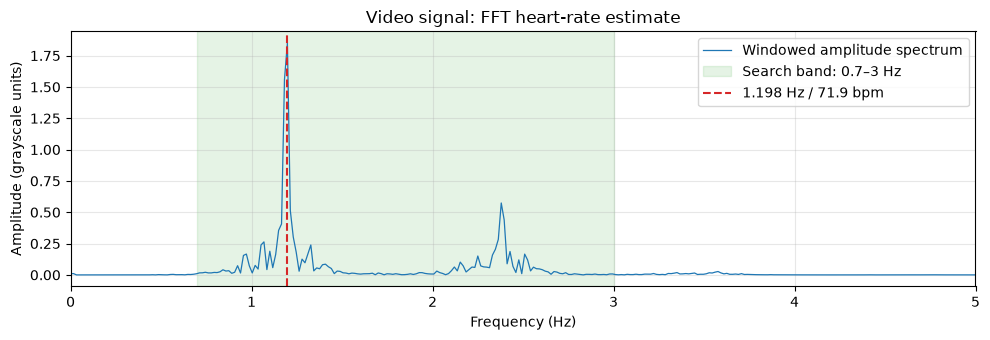

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.5))                                                               # Create a frequency-domain figure for the report.
ax.plot(freqs_v, amplitude_v, linewidth=0.9, label="Windowed amplitude spectrum")
ax.axvspan(*HR_BAND, color="tab:green", alpha=0.12, label="Search band: 0.7–3 Hz")                      # Show the allowed frequency range.
ax.axvline(f_peak_v, color="tab:red", linestyle="--", label=f"{f_peak_v:.3f} Hz / {hr_fft_v:.1f} bpm")  # Mark the selected peak.
ax.set(xlim=(0, min(5, fs_v / 2)), xlabel="Frequency (Hz)", ylabel="Amplitude (grayscale units)", title="Video signal: FFT heart-rate estimate")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/B3_fft_spectrum.png", dpi=200)                                                     # Save a labelled spectrum for the report.
plt.show()

## B.7 Cross-check using time-domain peaks

This supplementary check measures intervals between detected maxima. A prominence threshold of 0.5 times the signal standard deviation is a starting choice to inspect on the plot, not a validated universal threshold. 

Detected maxima: 73
Peak-interval estimate: 71.9 bpm; difference from FFT: 0.0 bpm


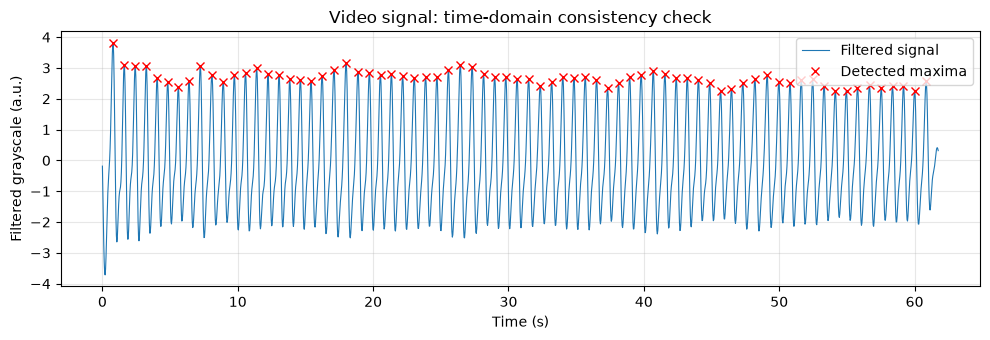

In [ ]:
min_gap_v = max(1, int(np.ceil(fs_v / HR_BAND[1])))                                           # Enforce the minimum interval associated with the upper search frequency.
peaks_v, _ = find_peaks(v_filtered, distance=min_gap_v, prominence=0.5 * np.std(v_filtered))  # Detect prominent maxima in the filtered waveform.
ibi_v = np.diff(t_v[peaks_v])                                                                 # Calculate the time between consecutive detected peaks in seconds.
hr_peaks_v = 60 / np.mean(ibi_v) if len(ibi_v) else np.nan                                    # Return NaN if fewer than two peaks are detected.
print(f"Detected maxima: {len(peaks_v)}")
if np.isfinite(hr_peaks_v):
    print(f"Peak-interval estimate: {hr_peaks_v:.1f} bpm; difference from FFT: {abs(hr_peaks_v - hr_fft_v):.1f} bpm")
else:
    print("Insufficient peaks for an interval-based estimate; inspect the waveform.")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_v, v_filtered, linewidth=0.8, label="Filtered signal")
ax.plot(t_v[peaks_v], v_filtered[peaks_v], "rx", label="Detected maxima")  # Make missed or extra detections visible.
ax.set(xlabel="Time (s)", ylabel="Filtered grayscale (a.u.)", title="Video signal: time-domain consistency check")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/B4_peak_check.png", dpi=200)
plt.show()

Observation: When rounding to one decimal place, both methods yield a result of 71.9 bpm. The results differ by approximately 0.038 bpm without rounding, which explains why the displayed difference is 0.0 bpm. This supports the use of both methods for consistency testing on the same filtered signal. However, reference measurements still need to be carried out simultaneously to assess accuracy.

## B.8 Check stability in separate time segments

Estimate heart rate in non-overlapping 15-second segments. An incomplete final segment is omitted. Shorter segments have coarser FFT spacing, so changes can reflect both estimation variability and physiological changes. 

In [ ]:
segment_samples_v = int(round(15 * fs_v))                                                                     # Use approximately 15 seconds per complete segment.
segment_rows_v = []
for start_v in range(0, len(v_filtered) - segment_samples_v + 1, segment_samples_v):
    stop_v = start_v + segment_samples_v                                                                      # Select one complete, non-overlapping segment.
    segment_hr_v, _, _, _ = video_fft_hr(v_filtered[start_v:stop_v], fs_v)                                    # Apply the same windowed FFT method.
    segment_rows_v.append({"start_s": t_v[start_v], "end_s": t_v[stop_v - 1] + 1 / fs_v, "heart_rate_bpm": segment_hr_v, "bin_spacing_bpm": 60 * fs_v / segment_samples_v})
segments_B = pd.DataFrame(segment_rows_v, columns=["start_s", "end_s", "heart_rate_bpm", "bin_spacing_bpm"])  # Keep a consistent table even for short recordings.
print(segments_B.to_string(index=False))
if len(segments_B) >= 2:
    print(f"Segment estimates span {segments_B.heart_rate_bpm.min():.1f}–{segments_B.heart_rate_bpm.max():.1f} bpm.")

  start_s     end_s  heart_rate_bpm  bin_spacing_bpm
 0.000000 15.010934       71.947554         3.997086
15.010934 30.021868       71.947554         3.997086
30.021868 45.032802       71.947554         3.997086
45.032802 60.043737       71.947554         3.997086
Segment estimates span 71.9–71.9 bpm.


Observation: All four sections were selected using the same FFT bin, with an estimated value of approximately 71.9 bpm. However, the bin spacing for each section is approximately 4 bpm, so small changes may not be resolved. The results support the stability of this frequency-grid spacing, while allowing for minor variations both within and between sections.

## B.9 Save the numerical results and processed data



In [ ]:
results_B = pd.DataFrame({"method": ["Windowed FFT", "Peak intervals"], "heart_rate_bpm": [hr_fft_v, hr_peaks_v]})                   # Keep both estimates without rounding the saved data.
results_B.to_csv("data/partB_results.csv", index=False)                                                                              # Save the final estimate table.
pd.DataFrame({"time_s": t_v, "filtered_signal": v_filtered}).to_csv("data/partB_filtered_signal.csv", index=False)                   # Save the processed time series.
pd.DataFrame({"frequency_hz": freqs_v, "amplitude": amplitude_v}).to_csv("data/partB_fft_spectrum.csv", index=False)                 # Save the spectrum for reproducibility.
pd.DataFrame({"peak_time_s": t_v[peaks_v], "peak_value": v_filtered[peaks_v]}).to_csv("data/partB_detected_peaks.csv", index=False)  # Save peak locations for inspection.
segments_B.to_csv("data/partB_segment_results.csv", index=False)                                                                     # Save the segment consistency check.
print(results_B.to_string(index=False))
print("Saved Part B figures and CSV outputs.")

        method  heart_rate_bpm
  Windowed FFT       71.869857
Peak intervals       71.907606
Saved Part B figures and CSV outputs.
